# Huấn luyện bộ phân loại cử chỉ tay

**Đề tài:** AI Hand-Gesture Authenticated Smart Door Lock — hệ thống IoT 4 tầng

Notebook này huấn luyện một mạng nơ-ron nhỏ (MLP) để phân loại **7 lớp cử chỉ**
từ vector đặc trưng **42 chiều** do `common.preprocess_landmarks()` sinh ra.

| Bước | Nội dung |
|---|---|
| 1 | Nạp thư viện và cấu hình |
| 2 | Đọc `model/keypoint.csv` và kiểm tra dữ liệu |
| 3 | Chia train/validation 80/20 có phân tầng |
| 4 | Dựng mạng MLP |
| 5 | Huấn luyện với EarlyStopping |
| 6 | Đánh giá: classification report + ma trận nhầm lẫn |
| 7 | Lưu model `.keras` và `.tflite` |
| 8 | Độ chính xác từng lớp và cảnh báo cặp lớp dễ nhầm |

> **Chạy notebook này TRƯỚC KHI** chạy `gesture_lock.py`, vì `gesture_lock.py`
> nạp file `.tflite` do bước 7 sinh ra.
>
> Yêu cầu: đã chạy `collect_data.py` và thu **250–300 mẫu mỗi lớp**, kể cả lớp `none`.

## Bước 1 — Nạp thư viện và cấu hình

Mọi tham số (đường dẫn, danh sách lớp) đều đọc từ `config.json`, không viết cứng
trong notebook. Nhờ vậy sửa một chỗ là cả hệ thống đổi theo.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Cho phép import common.py nằm cùng thư mục vision/
VISION_DIR = Path.cwd()
if not (VISION_DIR / "common.py").exists():          # phòng khi mở notebook từ gốc dự án
    VISION_DIR = VISION_DIR / "vision"
sys.path.insert(0, str(VISION_DIR))

from common import load_config, gesture_tables, resolve_path, FEATURE_DIM

cfg = load_config(VISION_DIR / "config.json")
ID_TO_LABEL, _ = gesture_tables(cfg)
CLASS_NAMES = [ID_TO_LABEL[i] for i in sorted(ID_TO_LABEL)]
NUM_CLASSES = len(CLASS_NAMES)

CSV_PATH     = resolve_path(cfg["model"]["keypoint_csv"])
KERAS_PATH   = resolve_path(cfg["model"]["classifier_keras"])
TFLITE_PATH  = resolve_path(cfg["model"]["classifier_tflite"])
CM_PNG_PATH  = (VISION_DIR.parent / "docs" / "confusion_matrix.png").resolve()

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow :", tf.__version__)
print("So chieu dac trung :", FEATURE_DIM)
print("So lop             :", NUM_CLASSES, "->", CLASS_NAMES)
print("File du lieu       :", CSV_PATH)

# ===================================================================
#  CO TRON HaGRID VAO TAP TRAIN?  —  MAC DINH PHAI LA False
# ===================================================================
#  False (mac dinh):
#     HaGRID la TAP KIEM THU DOC LAP. Model chi hoc tu du lieu tu thu bang
#     webcam, va vision/eval_external.py do duoc dung cau hoi:
#     "model co nhan duoc ban tay cua NGUOI KHAC khong".
#
#  True:
#     HaGRID duoc noi vao tap train. KHI DO HaGRID KHONG CON LA TAP KIEM THU
#     DOC LAP NUA — con so cua eval_external.py mat y nghia, vi model da nhin
#     thay chinh du lieu do trong luc hoc.
#     Bat co nay thi PHAI ghi ro trong bao cao, va TUYET DOI khong duoc trinh
#     bay con so HaGRID nhu ket qua kiem thu doc lap.
USE_HAGRID_FOR_TRAINING = False

HAGRID_CSV = resolve_path("model/keypoint_hagrid.csv")
print("USE_HAGRID_FOR_TRAINING :", USE_HAGRID_FOR_TRAINING)


TensorFlow : 2.21.0
So chieu dac trung : 42
So lop             : 7 -> ['fist', 'palm', 'victory', 'thumb_up', 'point_up', 'ok', 'none']
File du lieu       : D:\IoT_Gesture_sequence_door_lock\vision\model\keypoint.csv
USE_HAGRID_FOR_TRAINING : False


### Về cờ `USE_HAGRID_FOR_TRAINING`

Cờ này nằm ở cell đầu và **mặc định là `False`**.

HaGRID được dùng làm **tập kiểm thử độc lập**: model học từ dữ liệu tự thu bằng webcam,
rồi `vision/eval_external.py` đo xem nó có nhận được bàn tay của *người khác* hay không.
Con số trên HaGRID sẽ thấp hơn tập validation tự thu — đó là kết quả đúng và trung thực,
không phải lỗi. Khoảng cách giữa hai con số chính là thứ đáng đưa vào báo cáo.

Nếu bật cờ lên `True`, HaGRID được nối vào tập train. **Khi đó HaGRID không còn là tập
kiểm thử độc lập nữa** — model đã nhìn thấy chính dữ liệu đó lúc học, nên con số của
`eval_external.py` mất ý nghĩa kiểm thử. Bật cờ thì phải ghi rõ trong báo cáo.

## Bước 2 — Đọc dữ liệu và kiểm tra

Định dạng `keypoint.csv`: mỗi dòng là 1 mẫu, **cột 1** là `class_id`, **42 cột sau**
là vector đặc trưng.

Ba thứ cần kiểm tra trước khi train, vì nếu sai thì train xong mới phát hiện sẽ rất mất công:

1. **Số cột đúng 43** — sai nghĩa là khâu tiền xử lý đã đổi mà dữ liệu cũ còn lẫn vào.
2. **Không có NaN** — một dòng NaN đủ làm toàn bộ loss thành NaN.
3. **Các lớp cân bằng** — lớp nào quá ít mẫu thì model gần như không học được lớp đó.

In [2]:
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Chua co {CSV_PATH}.\n"
        f"Hay chay thu du lieu truoc:\n"
        f'  D:\\IoT_Gesture_sequence_door_lock\\.conda\\python.exe vision\\collect_data.py'
    )

data = np.loadtxt(CSV_PATH, delimiter=",", dtype=np.float32)
if data.ndim == 1:                      # phong truong hop file chi co 1 dong
    data = data.reshape(1, -1)

X = data[:, 1:]
y = data[:, 0].astype(np.int32)

print("Kich thuoc file :", data.shape)

# --- Kiem tra 1: so cot ---
assert data.shape[1] == FEATURE_DIM + 1, (
    f"Moi dong phai co {FEATURE_DIM + 1} cot (1 nhan + {FEATURE_DIM} dac trung), "
    f"dang co {data.shape[1]}. Co the file CSV lan du lieu cu."
)

# --- Kiem tra 2: NaN ---
n_nan = int(np.isnan(X).sum())
assert n_nan == 0, f"Co {n_nan} gia tri NaN trong du lieu. Xoa cac dong hong roi chay lai."

# --- Tuy chon: noi HaGRID vao tap train (xem canh bao o cell dau) ---
if USE_HAGRID_FOR_TRAINING:
    if not HAGRID_CSV.exists():
        raise FileNotFoundError(
            f"USE_HAGRID_FOR_TRAINING=True nhung chua co {HAGRID_CSV}.\n"
            "Chay kaggle/extract_hagrid_landmarks.ipynb tren Kaggle roi tai file ve."
        )
    dh = np.loadtxt(HAGRID_CSV, delimiter=",", dtype=np.float32)
    if dh.ndim == 1:
        dh = dh.reshape(1, -1)
    assert dh.shape[1] == FEATURE_DIM + 1, (
        f"keypoint_hagrid.csv phai co {FEATURE_DIM + 1} cot, dang co {dh.shape[1]}"
    )
    n_truoc = len(y)
    X = np.vstack([X, dh[:, 1:]])
    y = np.concatenate([y, dh[:, 0].astype(np.int32)])
    print()
    print("*" * 70)
    print("*  DA TRON HaGRID VAO TAP TRAIN                                      *")
    print(f"*  {n_truoc} mau tu thu + {len(dh)} mau HaGRID = {len(y)} mau" .ljust(69) + "*")
    print("*  HaGRID KHONG con la tap kiem thu doc lap. Con so cua              *")
    print("*  eval_external.py khong con y nghia kiem thu. Ghi ro vao bao cao.  *")
    print("*" * 70)
elif HAGRID_CSV.exists():
    print(f"(Co {HAGRID_CSV.name} nhung USE_HAGRID_FOR_TRAINING=False")
    print(" -> giu lam tap kiem thu doc lap, dung cho eval_external.py)")

# --- Kiem tra 3: phan bo lop ---
print()
print(f"{'id':<4}{'lop':<12}{'so mau':>8}{'ty le':>9}")
print("-" * 34)
for cid in sorted(ID_TO_LABEL):
    n = int((y == cid).sum())
    canh_bao = "  <-- qua it" if n < 100 else ""
    print(f"{cid:<4}{ID_TO_LABEL[cid]:<12}{n:>8}{n / len(y):>8.1%}{canh_bao}")
print("-" * 34)
print(f"{'':<16}{len(y):>8}  tong cong")

thieu = [ID_TO_LABEL[c] for c in sorted(ID_TO_LABEL) if (y == c).sum() == 0]
if thieu:
    raise ValueError(f"Chua co mau nao cho lop: {thieu}. Phai thu du 7 lop moi train duoc.")

Kich thuoc file : (2594, 43)
(Co keypoint_hagrid.csv nhung USE_HAGRID_FOR_TRAINING=False
 -> giu lam tap kiem thu doc lap, dung cho eval_external.py)

id  lop           so mau    ty le
----------------------------------
0   fist             358   13.8%
1   palm             398   15.3%
2   victory          420   16.2%
3   thumb_up         377   14.5%
4   point_up         300   11.6%
5   ok               374   14.4%
6   none             367   14.1%
----------------------------------
                    2594  tong cong


## Bước 3 — Chia train / validation

Chia **80% train / 20% validation**, có **phân tầng** (`stratify=y`) để tỉ lệ các lớp
trong tập validation giống tập train. Không phân tầng thì có thể cả một lớp rơi hết
vào tập train, làm điểm validation không còn ý nghĩa.

`random_state=42` để mỗi lần chạy lại đều ra cùng một cách chia — cần thiết khi
so sánh các lần huấn luyện với nhau.

In [3]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("train:", X_train.shape, " validation:", X_val.shape)
print()
print(f"{'lop':<12}{'train':>8}{'val':>8}")
print("-" * 28)
for cid in sorted(ID_TO_LABEL):
    print(f"{ID_TO_LABEL[cid]:<12}{int((y_train == cid).sum()):>8}{int((y_val == cid).sum()):>8}")

train: (2075, 42)  validation: (519, 42)

lop            train     val
----------------------------
fist             286      72
palm             318      80
victory          336      84
thumb_up         302      75
point_up         240      60
ok               299      75
none             294      73


## Bước 4 — Dựng mạng MLP

```
Input(42)
  -> Dropout(0.2)
  -> Dense(20, relu)
  -> Dropout(0.4)
  -> Dense(10, relu)
  -> Dense(7, softmax)
```

Mạng **cố tình làm rất nhỏ** (chỉ ~1 nghìn tham số). Lý do:

- Đầu vào đã được chuẩn hoá kỹ ở `preprocess_landmarks()` (bỏ vị trí, bỏ kích thước,
  quy tay trái về tay phải), nên bài toán còn lại khá dễ — không cần mạng lớn.
- Dữ liệu chỉ vài nghìn mẫu. Mạng lớn sẽ **học thuộc** dữ liệu thay vì học quy luật.
- Mạng nhỏ chạy được ở tốc độ camera thời gian thực trên CPU laptop.

Hai lớp `Dropout` chính là để chống học thuộc: mỗi bước huấn luyện ngẫu nhiên tắt bớt
nơ-ron, buộc mạng không được phụ thuộc vào một vài đặc trưng riêng lẻ.

Dùng `sparse_categorical_crossentropy` vì nhãn đang ở dạng số nguyên `0..6`
(nếu dùng `categorical_crossentropy` thì phải one-hot hoá trước).

In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(FEATURE_DIM,)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout (Dropout)               │ (None, 42)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │           860 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │            77 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,147 (4.48 KB)

 Trainable params: 1,147 (4.48 KB)

 Non-trainable params: 0 (0.00 B)

## Bước 5 — Huấn luyện

`EarlyStopping(patience=20)` theo dõi `val_loss`: nếu qua **20 epoch liên tiếp** mà
validation không khá lên thì dừng, và `restore_best_weights=True` lấy lại trọng số
của epoch tốt nhất chứ không giữ trọng số của epoch cuối.

Nhờ đó đặt `epochs=1000` cũng không sao — thực tế sẽ tự dừng sớm hơn nhiều.

In [5]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1,
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=128,
    callbacks=[early_stop],
    verbose=2,
)

print()
print("So epoch da chay :", len(history.history["loss"]))
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"val_loss = {val_loss:.4f}   val_accuracy = {val_acc:.4f}")

Epoch 1/1000
17/17 - 3s - 168ms/step - accuracy: 0.1807 - loss: 1.9550 - val_accuracy: 0.3121 - val_loss: 1.9020
Epoch 2/1000
17/17 - 0s - 13ms/step - accuracy: 0.2120 - loss: 1.9209 - val_accuracy: 0.3179 - val_loss: 1.8793
Epoch 3/1000
17/17 - 0s - 12ms/step - accuracy: 0.2448 - loss: 1.8930 - val_accuracy: 0.3102 - val_loss: 1.8534
Epoch 4/1000
17/17 - 0s - 20ms/step - accuracy: 0.2501 - loss: 1.8626 - val_accuracy: 0.3121 - val_loss: 1.8224
Epoch 5/1000
17/17 - 0s - 11ms/step - accuracy: 0.2593 - loss: 1.8495 - val_accuracy: 0.2987 - val_loss: 1.7905
Epoch 6/1000
17/17 - 0s - 11ms/step - accuracy: 0.2708 - loss: 1.8185 - val_accuracy: 0.3121 - val_loss: 1.7603
Epoch 7/1000
17/17 - 0s - 10ms/step - accuracy: 0.2824 - loss: 1.7922 - val_accuracy: 0.3314 - val_loss: 1.7275
Epoch 8/1000
17/17 - 1s - 30ms/step - accuracy: 0.2930 - loss: 1.7717 - val_accuracy: 0.3757 - val_loss: 1.6949
Epoch 9/1000
17/17 - 0s - 27ms/step - accuracy: 0.2959 - loss: 1.7587 - val_accuracy: 0.4509 - val_loss

### Đường học

Hai đường `train` và `validation` bám sát nhau là tốt. Nếu đường train tiếp tục giảm
mà đường validation đi ngang rồi ngóc lên, đó là dấu hiệu **học thuộc** — cần thu thêm
dữ liệu đa dạng hơn (đổi góc tay, đổi ánh sáng, đổi khoảng cách).

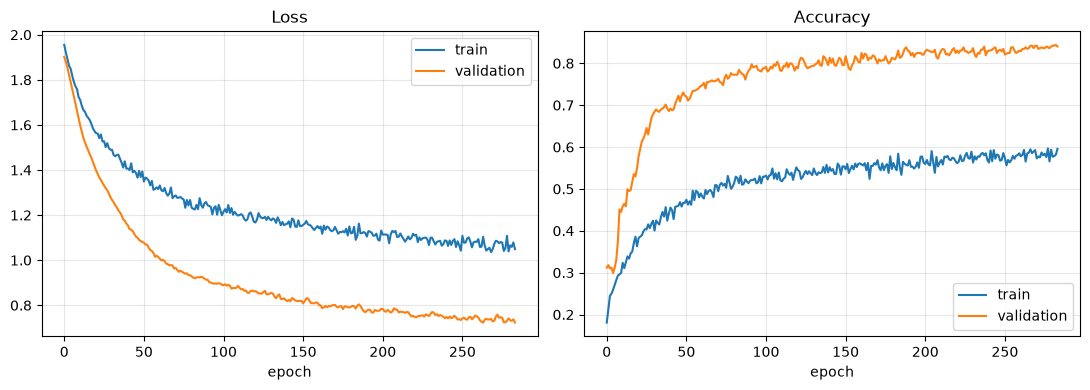

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

## Bước 6 — Đánh giá trên tập validation

`classification_report` cho 3 con số mỗi lớp:

- **precision** — trong những lần model kêu là lớp X, bao nhiêu phần trăm đúng.
  Thấp nghĩa là model hay **báo nhầm** thành lớp X.
- **recall** — trong những mẫu thật sự là lớp X, model bắt được bao nhiêu phần trăm.
  Thấp nghĩa là model hay **bỏ sót** lớp X.
- **f1-score** — trung bình điều hoà của hai cái trên.

Với bài khoá cửa này, **precision của các lớp cử chỉ quan trọng hơn recall**: báo nhầm
một cử chỉ sẽ làm sai mã và bị khoá, còn bỏ sót thì người dùng chỉ cần giữ tay lâu hơn.

In [7]:
y_pred = np.argmax(model.predict(X_val, verbose=0), axis=1)

print(classification_report(
    y_val, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

        fist      0.805     0.861     0.832        72
        palm      0.949     0.925     0.937        80
     victory      0.893     0.893     0.893        84
    thumb_up      0.926     0.840     0.881        75
    point_up      0.727     0.800     0.762        60
          ok      0.840     0.840     0.840        75
        none      0.704     0.685     0.694        73

    accuracy                          0.838       519
   macro avg      0.835     0.835     0.834       519
weighted avg      0.841     0.838     0.839       519



### Ma trận nhầm lẫn

Đọc theo **hàng**: hàng `i` là các mẫu thật sự thuộc lớp `i`, cột `j` là số mẫu bị
model đoán thành lớp `j`. Đường chéo là đoán đúng. Ô sáng nằm ngoài đường chéo chính
là **cặp cử chỉ bị nhầm** — đó là chỗ cần thu thêm dữ liệu.

Hình được lưu ra `docs/confusion_matrix.png` để đưa vào báo cáo.

Da luu: D:\IoT_Gesture_sequence_door_lock\docs\confusion_matrix.png


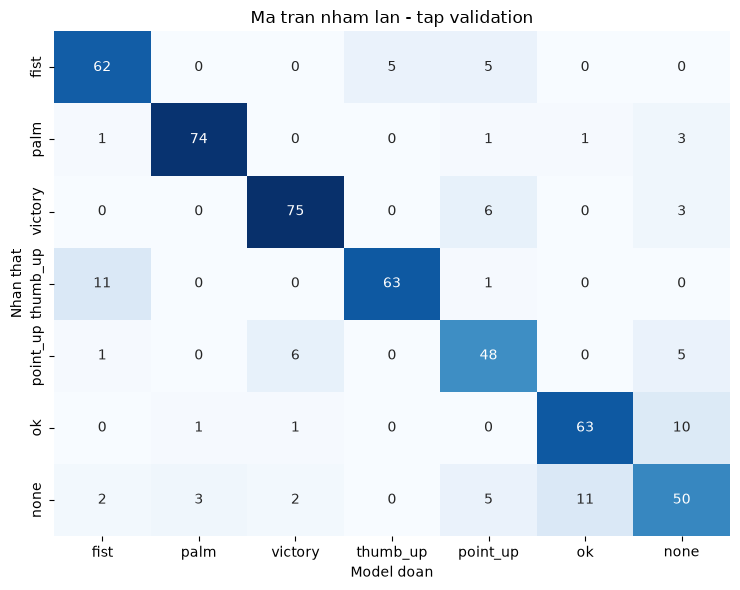

In [8]:
cm = confusion_matrix(y_val, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(7.5, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
)
plt.xlabel("Model doan")
plt.ylabel("Nhan that")
plt.title("Ma tran nham lan - tap validation")
plt.tight_layout()

CM_PNG_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(CM_PNG_PATH, dpi=150)
print("Da luu:", CM_PNG_PATH)
plt.show()

## Bước 7 — Lưu model

Lưu **hai** định dạng:

- **`.keras`** — bản gốc đầy đủ, để sau này train tiếp hoặc phân tích.
- **`.tflite`** — bản rút gọn, đây mới là bản mà `gesture_lock.py` nạp lúc chạy thật.
  TFLite khởi động nhanh hơn và nhẹ hơn nhiều so với nạp cả TensorFlow.

Ô cuối **đối chiếu hai model trên cùng dữ liệu**. Bước này nhìn thừa nhưng rất cần:
nếu chuyển đổi TFLite hỏng, model vẫn chạy và vẫn trả về số, chỉ là trả về **sai** —
lúc đó rất khó lần ra vì `gesture_lock.py` sẽ chỉ đơn giản là đoán lung tung.

In [9]:
KERAS_PATH.parent.mkdir(parents=True, exist_ok=True)
model.save(KERAS_PATH)
print("Da luu Keras :", KERAS_PATH, f"({KERAS_PATH.stat().st_size / 1024:.0f} KB)")

# Keras 3 khuyen dung duong export -> SavedModel -> TFLite.
# Van thu from_keras_model truoc vi no gon hon, hong thi quay ve cach kia.
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_bytes = converter.convert()
except Exception as e:
    print("from_keras_model khong dung duoc:", type(e).__name__, "- chuyen sang SavedModel")
    import tempfile
    with tempfile.TemporaryDirectory() as tmp:
        model.export(tmp)
        converter = tf.lite.TFLiteConverter.from_saved_model(tmp)
        tflite_bytes = converter.convert()

TFLITE_PATH.write_bytes(tflite_bytes)
print("Da luu TFLite:", TFLITE_PATH, f"({len(tflite_bytes) / 1024:.0f} KB)")

Da luu Keras : D:\IoT_Gesture_sequence_door_lock\vision\model\gesture_classifier.keras (43 KB)
INFO:tensorflow:Assets written to: C:\Users\KHOALE~1\AppData\Local\Temp\tmpcp2kyt2u\assets


INFO:tensorflow:Assets written to: C:\Users\KHOALE~1\AppData\Local\Temp\tmpcp2kyt2u\assets


Saved artifact at 'C:\Users\KHOALE~1\AppData\Local\Temp\tmpcp2kyt2u'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 42), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  1880445098064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1880445099408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1880289497488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1880290640912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1880765851088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1880765850128: TensorSpec(shape=(), dtype=tf.resource, name=None)
Da luu TFLite: D:\IoT_Gesture_sequence_door_lock\vision\model\gesture_classifier.tflite (7 KB)


In [10]:
# Doi chieu TFLite voi Keras tren toan bo tap validation.
interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

tflite_pred = []
for row in X_val:
    interpreter.set_tensor(inp["index"], row.reshape(1, -1).astype(np.float32))
    interpreter.invoke()
    tflite_pred.append(int(np.argmax(interpreter.get_tensor(out["index"])[0])))
tflite_pred = np.array(tflite_pred)

khop = float((tflite_pred == y_pred).mean())
print(f"Ty le TFLite trung khop voi Keras: {khop:.4%}")
if khop < 0.999:
    print("CANH BAO: hai model lech nhau. KHONG dung file .tflite nay, kiem tra lai buoc chuyen doi.")
else:
    print("OK - file .tflite dung duoc cho gesture_lock.py")

Ty le TFLite trung khop voi Keras: 100.0000%
OK - file .tflite dung duoc cho gesture_lock.py


d:\IoT_Gesture_sequence_door_lock\.conda\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## Bước 8 — Độ chính xác từng lớp và cảnh báo cặp dễ nhầm

Ô cuối cùng trả lời đúng một câu hỏi: **cử chỉ nào chưa dùng được?**

Ngưỡng cảnh báo là **10%** — nghĩa là nếu cứ 10 lần làm cử chỉ A thì có hơn 1 lần
model đọc thành B, cặp (A, B) bị coi là chưa đạt.

Với hệ khoá cửa cần 3 cử chỉ liên tiếp, sai số dồn lại rất nhanh: mỗi cử chỉ đúng 90%
thì cả chuỗi chỉ còn `0.9³ ≈ 73%` — cứ 4 lần mở cửa là hỏng 1 lần.

**Cách xử lý khi có cảnh báo:**
1. Thu thêm 100–150 mẫu cho **cả hai** lớp trong cặp bị nhầm, cố ý làm ở nhiều góc
   tay và khoảng cách khác nhau, rồi train lại.
2. Nếu vẫn nhầm, **đổi mật mã** sang cặp cử chỉ khác — cách này nhanh và chắc ăn hơn.

In [12]:
NGUONG_CANH_BAO = 0.10

print("DO CHINH XAC TUNG LOP (tren tap validation)")
print("-" * 46)
print(f"{'lop':<12}{'so mau':>8}{'dung':>7}{'do chinh xac':>15}")
print("-" * 46)
for i, ten in enumerate(CLASS_NAMES):
    tong = int(cm[i].sum())
    dung = int(cm[i, i])
    if tong == 0:
        print(f"{ten:<12}{0:>8}{'-':>7}{'khong co mau':>15}")
        continue
    acc = dung / tong
    danh_dau = "" if acc >= 0.95 else ("  <-- yeu" if acc >= 0.85 else "  <-- RAT YEU")
    print(f"{ten:<12}{tong:>8}{dung:>7}{acc:>14.1%}{danh_dau}")
print("-" * 46)

# --- Cac cap lop nham nhau qua nguong ---
canh_bao = []
for i in range(NUM_CLASSES):
    tong = int(cm[i].sum())
    if tong == 0:
        continue
    for j in range(NUM_CLASSES):
        if i == j:
            continue
        ty_le = cm[i, j] / tong
        if ty_le > NGUONG_CANH_BAO:
            canh_bao.append((ty_le, CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]), tong))

print()
if not canh_bao:
    print(f"OK - khong co cap lop nao nham nhau qua {NGUONG_CANH_BAO:.0%}.")
    print("Model du tot de chay gesture_lock.py.")
else:
    print(f"CANH BAO - co {len(canh_bao)} cap lop nham nhau tren {NGUONG_CANH_BAO:.0%}:")
    print()
    for ty_le, that, doan, so_lan, tong in sorted(canh_bao, reverse=True):
        print(f"  '{that}' bi doan thanh '{doan}': {so_lan}/{tong} = {ty_le:.1%}")
    print()
    print("Xu ly: thu them du lieu cho CA HAI lop trong moi cap roi train lai,")
    print("hoac doi mat ma sang cu chi khac (sua secret.default_code trong config.json")
    print("va bien MA_MAC_DINH trong middleware/flows.json).")

# --- Nhac rieng ve cac cu chi dang nam trong mat ma ---
ma = cfg["secret"]["default_code"]
hex_to_label = {g["hex"]: g["label"] for g in cfg["gestures"] if g["hex"]}
trong_ma = [hex_to_label.get(ma[k:k + 2]) for k in range(0, len(ma), 2)]
print()
print(f"Mat ma hien tai '{ma}' dung cac cu chi: {trong_ma}")
lien_quan = [c for c in canh_bao if c[1] in trong_ma or c[2] in trong_ma]
if lien_quan:
    print("NGHIEM TRONG: cac cu chi trong mat ma dang nam trong cap bi nham.")
else:
    print("Cac cu chi trong mat ma khong nam trong cap nham nao.")

DO CHINH XAC TUNG LOP (tren tap validation)
----------------------------------------------
lop           so mau   dung   do chinh xac
----------------------------------------------
fist              72     62         86.1%  <-- yeu
palm              80     74         92.5%  <-- yeu
victory           84     75         89.3%  <-- yeu
thumb_up          75     63         84.0%  <-- RAT YEU
point_up          60     48         80.0%  <-- RAT YEU
ok                75     63         84.0%  <-- RAT YEU
none              73     50         68.5%  <-- RAT YEU
----------------------------------------------

CANH BAO - co 3 cap lop nham nhau tren 10%:

  'none' bi doan thanh 'ok': 11/73 = 15.1%
  'thumb_up' bi doan thanh 'fist': 11/75 = 14.7%
  'ok' bi doan thanh 'none': 10/75 = 13.3%

Xu ly: thu them du lieu cho CA HAI lop trong moi cap roi train lai,
hoac doi mat ma sang cu chi khac (sua secret.default_code trong config.json
va bien MA_MAC_DINH trong middleware/flows.json).

Mat ma hien tai 'E17C4